# Anomaly Detection — Kickoff Notebook

**Case holder:** Ishkhan Gorgisyan (ESS) · **Team captains:** Charly, Guillermo

This notebook does the same core trick as Monday's Lecture 02 notebook (train an
autoencoder on "normal" waveforms, use reconstruction error as an anomaly score) but on
**real ESS LLRF data** instead of a clean synthetic one. Real data is messier: there's no
confirmed fault label, and the raw signal doesn't quite behave the way its own field names
suggest. Both of those surprises are part of the notebook, not bugs to hide.

What's here:
1. Load a real sample of ESS `SDS_Data` events
2. A first look at the raw waveform — and a naming surprise worth flagging to the case holder
3. Feature engineering (physics-informed + statistical descriptors, scaled down from the
   SPIRAL2 LLRF pipeline's approach — see pointers at the end)
4. Unsupervised anomaly detection: autoencoder + reconstruction error (no ground truth, so
   evaluation is score-distribution/visual, not ROC-AUC like Monday)
5. Two more detectors on the same features — Isolation Forest and Local Outlier Factor —
   to see whether "anomalous" agrees across methods
6. Unsupervised classification of the anomalies: K-Means clustering into subtypes, same
   idea as the SPIRAL2 pipeline's fault-subtype clustering
7. A weakly-supervised bonus angle, with explainability via **SHAP** and **LIME**
8. A stretch pointer to the slow EPICS archiver data, for precursor-style analysis

Everything from section 4 on is a **pipeline of swappable pieces** — features, detector,
clustering, NN architecture. Section 7's weakly-supervised classifier and tiers Medium/Hard
in `objectives.md` are exactly where you tune those (architecture, hyperparameters,
feature set) and compare.

## Before you start

The full raw archive (71GB+ of `SDS_Data`/`Archiver_Data` tars) is **not in this
repository** — it lives on CC-IN2P3 storage at
`/sps/m4cast/artifact_hackathon_2026/anomaly-detection/raw/` (see the
[access guide](../../access-guide.md) for CC-IN2P3 account setup). This notebook runs
entirely on a small real sample in `data/sample/ess_llrf_sample.parquet` (210 events,
~0.5MB, built from that raw archive), so it works straight from a clone.

```
pip install -r requirements.txt
```

Autoencoder training is the slow part — a few minutes on a laptop CPU.

## 1. Setup

In [70]:
!pip install lime
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore", category=FutureWarning)
torch.manual_seed(42)
np.random.seed(42)
print("Imports OK")

Defaulting to user installation because normal site-packages is not writeable
Imports OK


## 2. Load a real sample of ESS LLRF data

Each row is one `SDS_Data` diagnostic (`DD`) capture: a single RF chain, one acquisition
cycle. `trig_code` looks like the EVR trigger/interlock code — i.e. *why* that capture was
taken — and does vary (14 vs 15 in this sample), correlated with `beam_mode`/`beam_state`.
That makes it a plausible weak label, **but it is not a confirmed fault label**: the case
holder hasn't published the scientific case yet, so treat any split on `trig_code` here as
exploratory, not ground truth.

In [52]:
!ls /workspace/lustre/work/pdl18409/shared/data/anomaly-detection/raw
import os
import pandas as pd

# Use the absolute path based on your workspace
df = pd.read_parquet("data/SDS_Data/20250528_2045_20250530_0416/DD/15643300300.parquet")

CANDIDATES = [
    # Update this with the exact filename you found using the !ls command
    os.path.join(BASE_DIR, "SDS_Data", "20250528_2045_20250530_0416", "DD", "15643300300", "HBL.parquet"),
    # os.path.join(BASE_DIR, "sample", "ess_llrf_sample.parquet")
]

SAMPLE_PATH = next((c for c in CANDIDATES if os.path.exists(c)), CANDIDATES[0])

if not os.path.exists(SAMPLE_PATH):
    raise FileNotFoundError(f"Could not find the file at {SAMPLE_PATH}. Please check the path.")

df = pd.read_parquet(SAMPLE_PATH)

print(f"Loaded {len(df)} events from {SAMPLE_PATH}")

Archiver_Data_lkrrd.tar
SDS_Data_20250528_2045_20250530_0416_DD_15643300300.tar_bgntn.gz
SDS_Data_20250528_2045_20250530_0416_DD_15643300300_jypcu.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642507892.tar_urjcd.gz
SDS_Data_20250528_2045_20250530_0416_PM_15642507892_ywooa.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642513562_hgwfu.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642516376_qatnk.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642519638_cgogo.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642520842_mbgnb.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642522046_ffyiy.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642523474_vprsx.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642663250_zhoia.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642807772_eqgps.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642826448_cqmum.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642862162_xyhyn.tar
SDS_Data_20250528_2045_20250530_0416_PM_15642886872_nlmae.tar
SDS_Data_20250528_2045_20250530_0416_PM_

FileNotFoundError: [Errno 2] No such file or directory: 'data/SDS_Data/20250528_2045_20250530_0416/DD/15643300300.parquet'

### Plot a selected PV

Select one value from the `pv` column and plot every matching `data_array` capture.

In [53]:
TARGET_PV = "HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData"

pv_rows = df.loc[df["pv"].eq(TARGET_PV)].sort_values("data_ts")
if pv_rows.empty:
    raise ValueError(f"PV not found: {TARGET_PV}")

fig, ax = plt.subplots(figsize=(12, 4))
for _, row in pv_rows.iterrows():
    timestamp = row["data_ts"].strftime("%H:%M:%S")
    ax.plot(np.asarray(row["data_array"]), alpha=0.7, label=timestamp)

ax.set_title(f"{TARGET_PV} ({len(pv_rows)} captures)")
ax.set_xlabel("sample index")
ax.set_ylabel("value")
ax.grid(alpha=0.25)
ax.legend(title="data_ts (UTC)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

In [90]:
!pwd
file = pd.read_pickle("dd_all_cycles.pkl")

/workspace/lustre/work/pdl18409/shared/Anomaly_Hunter


In [88]:
pd.set_option("display.max_colwidth", None)
print(file.pv.head(10))

0    HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData
1    HBL-010RFC:RFS-DIG-101:Dwn0-Cmp1SDS-DODData
2    HBL-010RFC:RFS-DIG-201:Dwn0-Cmp0SDS-DODData
3    HBL-010RFC:RFS-DIG-201:Dwn0-Cmp1SDS-DODData
4    HBL-010RFC:RFS-DIG-301:Dwn0-Cmp0SDS-DODData
5    HBL-010RFC:RFS-DIG-301:Dwn0-Cmp1SDS-DODData
6    HBL-010RFC:RFS-DIG-401:Dwn0-Cmp0SDS-DODData
7    HBL-010RFC:RFS-DIG-401:Dwn0-Cmp1SDS-DODData
8    HBL-010RFC:RFS-DIG-101:Dwn5-Cmp0SDS-DODData
9    HBL-010RFC:RFS-DIG-101:Dwn5-Cmp1SDS-DODData
Name: pv, dtype: object


### Plot the target PV from DD tar archives in `dd.list`

Read `dd.list` from the notebook folder. Select only `_DD_` archives and `HBL.parquet` members under a `DD` directory. Plot only the exact PV `HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData`; `PMData` is excluded. Archives are read in memory without extraction.
Both `/lustre/...` and `/workspace/lustre/...` archive paths are supported.


Selected 44/44 DD tar archives
DD HBL filter v2: exact PV = HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData
SDS_Data_20250528_2045_20250530_0416_DD_15643300300.tar_bgntn.gz: plotting PV=['HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData'] (9 captures)
SDS_Data_20250528_2045_20250530_0416_DD_15643300300_jypcu.tar: plotting PV=['HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData'] (9 captures)
Read 10/44 tar files
Read 20/44 tar files
Read 30/44 tar files
Read 40/44 tar files
Read 44/44 tar files


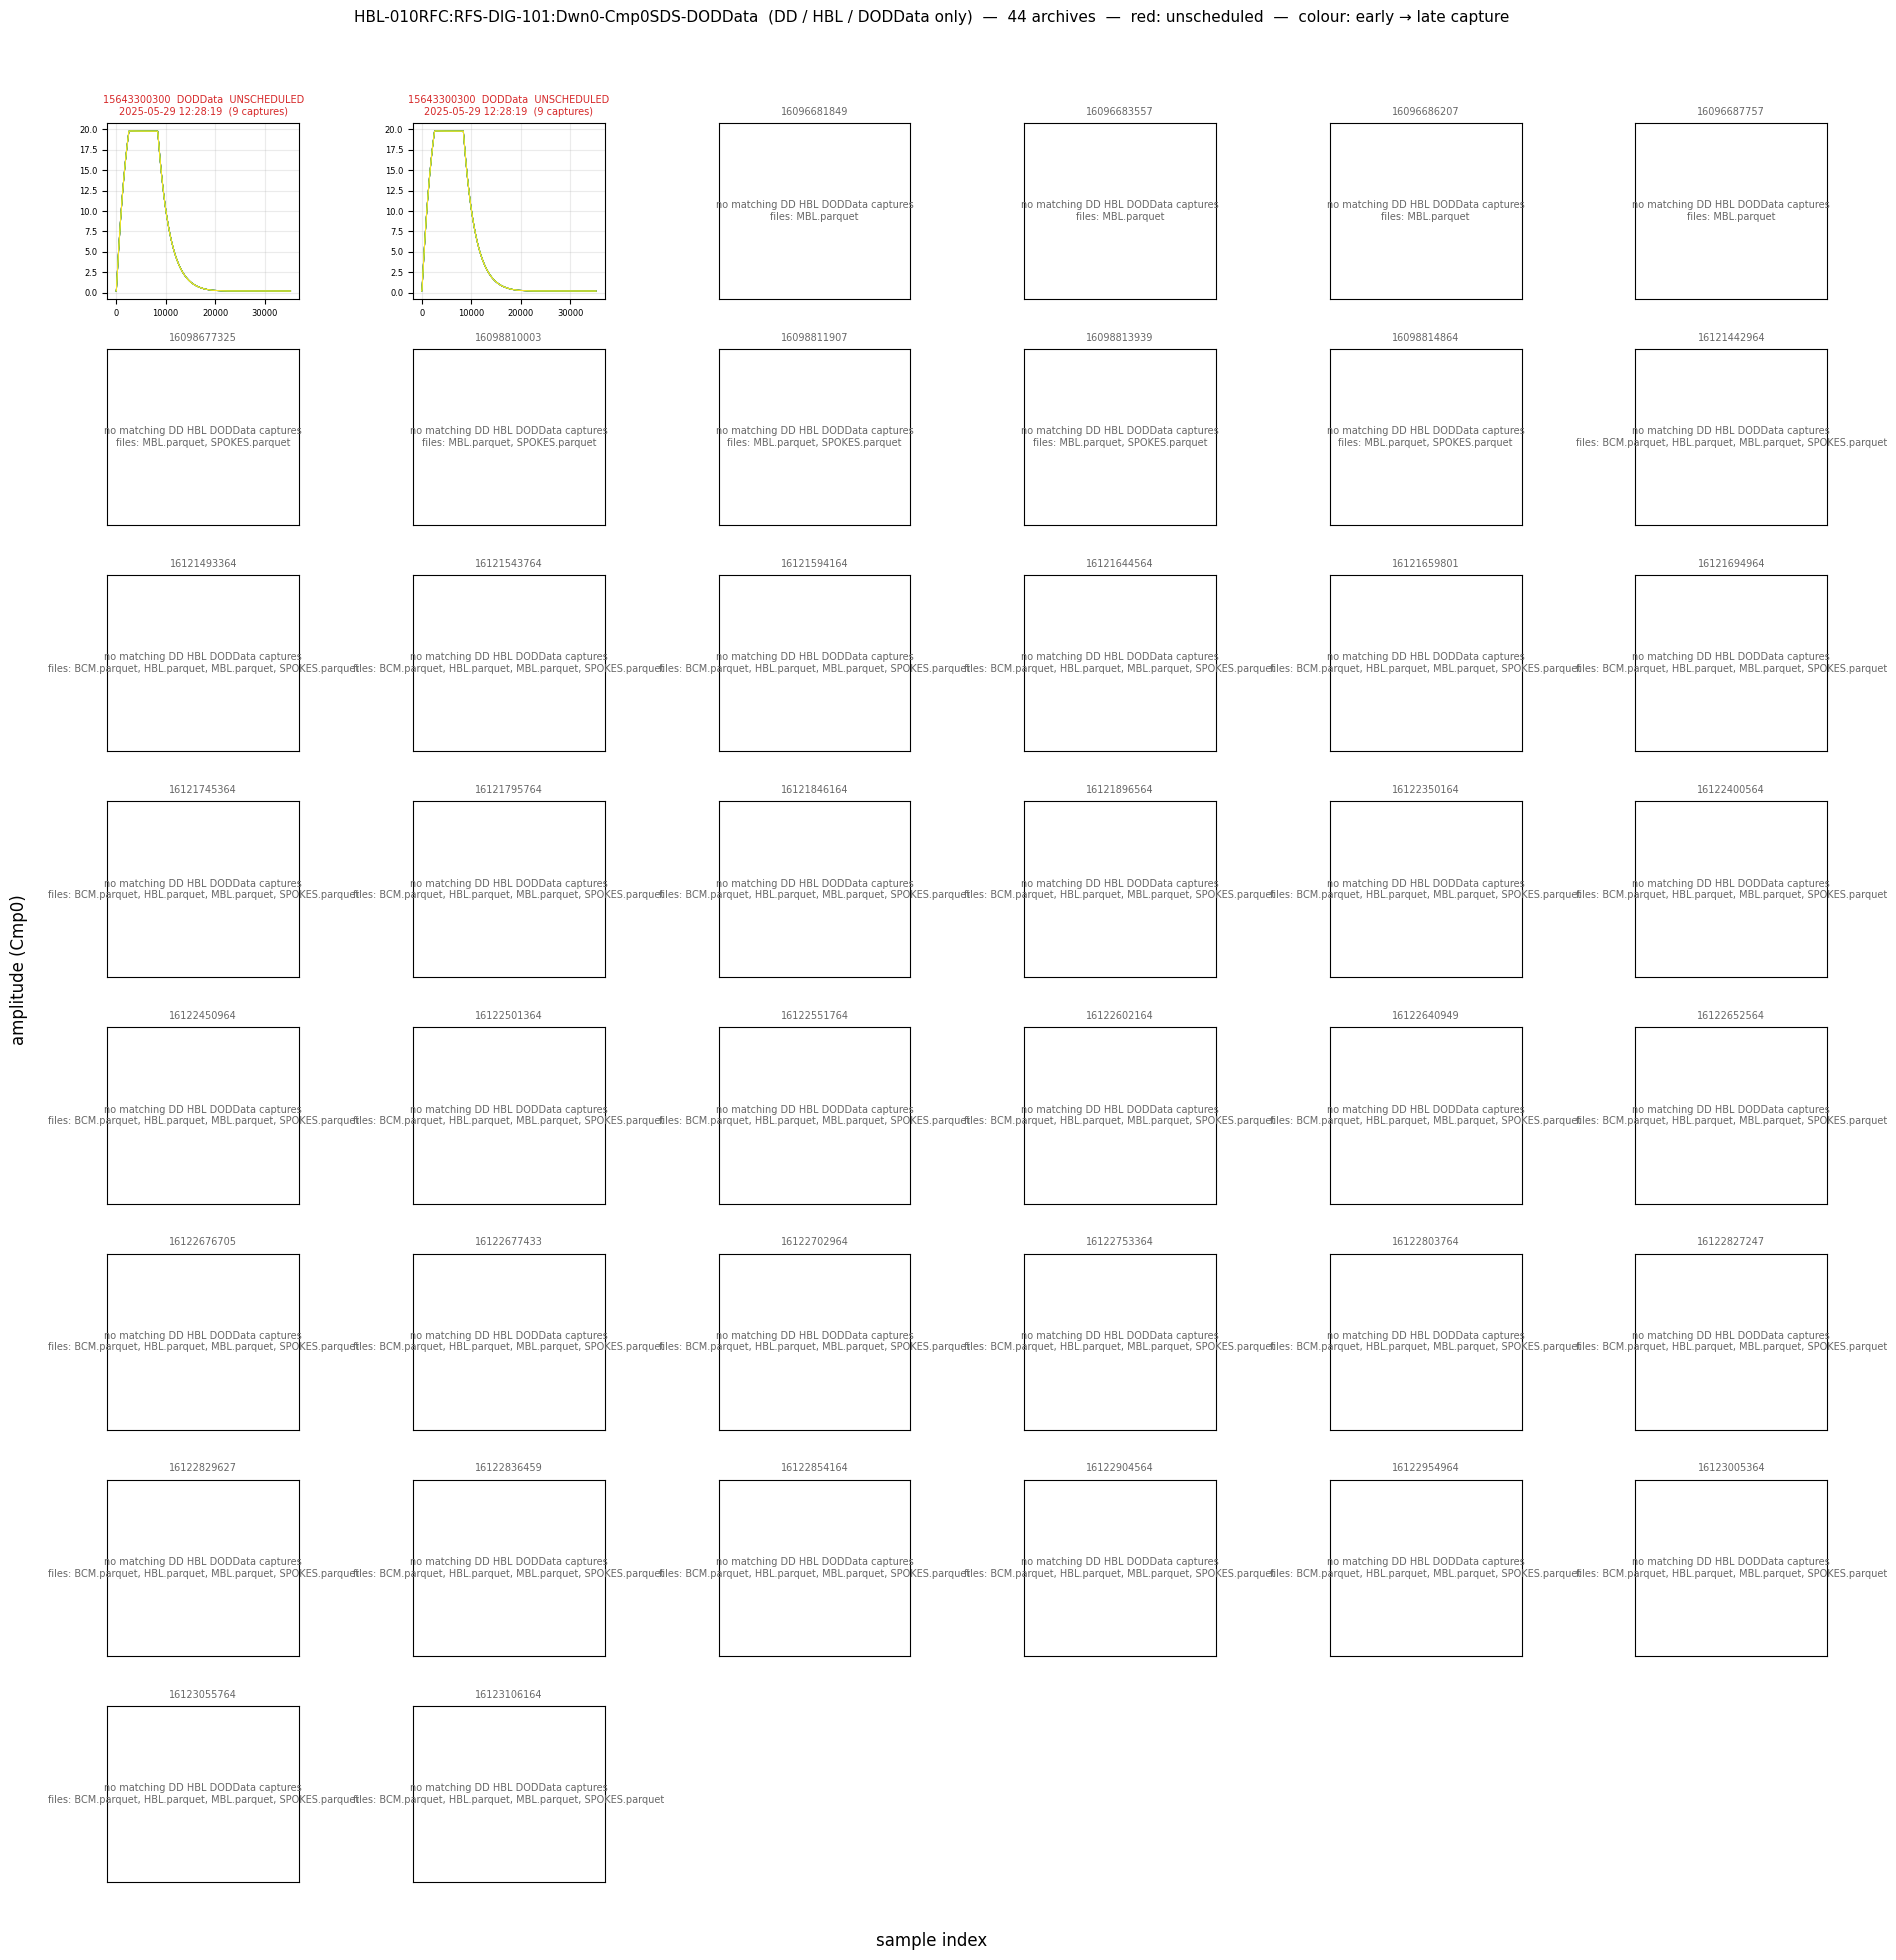

     capture_id  n_captures  pv_type                            first_ts               kind fingerprint
0   15643300300           9  DODData 2025-05-29 12:28:19.838728192+00:00        UNSCHEDULED      195754
1   15643300300           9  DODData 2025-05-29 12:28:19.838728192+00:00        UNSCHEDULED      195754
2   16096681849           0                                          NaT  no DD HBL DODData        None
3   16096683557           0                                          NaT  no DD HBL DODData        None
4   16096686207           0                                          NaT  no DD HBL DODData        None
5   16096687757           0                                          NaT  no DD HBL DODData        None
6   16098677325           0                                          NaT  no DD HBL DODData        None
7   16098810003           0                                          NaT  no DD HBL DODData        None
8   16098811907           0                                     

In [69]:
from io import BytesIO
from pathlib import Path
import re
import tarfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================ SETTINGS ============================
DD_LIST_PATH = Path("dd.list").resolve()                 # same folder as this notebook
TARGET_PV = "HBL-010RFC:RFS-DIG-101:Dwn0-Cmp0SDS-DODData"  # DD waveform only
HBL_FILE = "HBL.parquet"
MAX_PLOT_POINTS = 2_500                                  # display only; data unchanged
NCOLS = 6
# =================================================================

listed_tar_files = [Path(line.strip()) for line in DD_LIST_PATH.read_text().splitlines()
                    if line.strip() and not line.lstrip().startswith("#")]
def resolve_archive(path):
    path = path if path.is_absolute() else DD_LIST_PATH.parent / path
    candidates = [path]
    if path.is_relative_to("/lustre"):
        candidates.append(Path("/workspace") / path.relative_to("/"))
    elif path.is_relative_to("/workspace/lustre"):
        candidates.append(Path("/") / path.relative_to("/workspace"))
    return next((candidate for candidate in candidates if candidate.is_file()), path)


tar_files = [resolve_archive(p) for p in listed_tar_files if "_DD_" in p.name]
print(f"Selected {len(tar_files)}/{len(listed_tar_files)} DD tar archives")
if not tar_files:
    raise ValueError(f"No DD tar archives found in {DD_LIST_PATH}")
missing = [p for p in tar_files if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Files not found (first 3): {missing[:3]}")


def read_hbl(tar_path):
    """Return target HBL captures from DD directories and archive filenames."""
    frames, files = [], []
    with tarfile.open(tar_path, mode="r:*") as archive:
        for member in archive.getmembers():
            if not member.isfile():
                continue
            files.append(Path(member.name).name)
            member_path = Path(member.name)
            if member_path.name != HBL_FILE or "DD" not in member_path.parts[:-1]:
                continue                                    # DD/HBL only
            raw = archive.extractfile(member).read()
            frame = pd.read_parquet(BytesIO(raw),
                                    columns=["pv", "data_array", "data_ts"])
            # Filter the actual rows, independently of parquet engine pushdown.
            frame = frame.loc[frame["pv"].eq(TARGET_PV)].copy()
            if not frame.empty:
                frames.append(frame)
    rows = (pd.concat(frames, ignore_index=True).sort_values("data_ts")
            if frames else pd.DataFrame(columns=["pv", "data_array", "data_ts"]))
    return rows, files


print(f"DD HBL filter v2: exact PV = {TARGET_PV}")

nrows = int(np.ceil(len(tar_files) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.2 * NCOLS, 2.5 * nrows), squeeze=False)
summary = []

for index, (ax, tar_path) in enumerate(zip(axes.flat, tar_files), start=1):
    rows, files = read_hbl(tar_path)
    n = len(rows)
    if n and not rows["pv"].eq(TARGET_PV).all():
        raise ValueError(f"Unexpected PV before plotting: {rows['pv'].unique().tolist()}")
    if n:
        print(f"{tar_path.name}: plotting PV={rows['pv'].unique().tolist()} ({n} captures)")

    for k, arr in enumerate(rows["data_array"]):            # every capture, early → late
        values = np.asarray(arr)
        step = max(1, int(np.ceil(values.size / MAX_PLOT_POINTS)))
        ax.plot(np.arange(0, values.size, step), values[::step], linewidth=0.7,
                color=plt.cm.viridis(k / max(n - 1, 1)))

    match = re.search(r"_DD_(\d+)", tar_path.name)
    cap_id = match.group(1) if match else tar_path.name[:20]

    if n:
        kinds = sorted({pv.split("SDS-")[-1] for pv in rows["pv"]})
        t0 = rows["data_ts"].min()
        scheduled = t0.minute == 20 and t0.second == 26
        kind = "scheduled" if scheduled else "UNSCHEDULED"
        ax.set_title(f"{cap_id}  {'/'.join(kinds)}  {kind}\n"
                     f"{t0:%Y-%m-%d %H:%M:%S}  ({n} captures)", fontsize=7,
                     color="black" if scheduled else "tab:red")
        fingerprint = f"{np.asarray(rows['data_array'].iloc[0], dtype=float).sum():.6g}"
    else:
        kinds, t0, kind, fingerprint = [], pd.NaT, "no DD HBL DODData", None
        ax.text(0.5, 0.5, "no matching DD HBL DODData captures\nfiles: " + ", ".join(sorted(set(files))),
                ha="center", va="center", fontsize=7, color="0.4", transform=ax.transAxes)
        ax.set_title(cap_id, fontsize=7, color="0.4")
        ax.set_xticks([]); ax.set_yticks([])

    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=6)
    summary.append(dict(archive=tar_path.name, capture_id=cap_id, n_captures=n,
                        pv_type="/".join(kinds), first_ts=t0, kind=kind,
                        fingerprint=fingerprint, files=", ".join(sorted(set(files)))))
    if index % 10 == 0 or index == len(tar_files):
        print(f"Read {index}/{len(tar_files)} tar files")

for ax in axes.flat[len(tar_files):]:
    ax.set_visible(False)

fig.suptitle(f"{TARGET_PV}  (DD / HBL / DODData only)  —  {len(tar_files)} archives  —  "
             "red: unscheduled  —  colour: early → late capture", fontsize=11)
fig.supxlabel("sample index"); fig.supylabel("amplitude (Cmp0)")
plt.tight_layout(rect=(0.02, 0.02, 1, 0.96))
plt.show()

summary = pd.DataFrame(summary)
pd.set_option("display.width", 220)
print(summary[["capture_id", "n_captures", "pv_type", "first_ts", "kind", "fingerprint"]].to_string())
print("\n", summary.groupby("kind").size().to_string())

In [94]:
"""
make_ae_dataset.py
Build a small autoencoder dataset from ESS LLRF SDS data: N_CYCLES cycles of one RF
section (default HBL), with the beam condition of every cycle measured from the BCM data.

Why the beam matters: when protons pass, they draw power from the cavities (beam loading),
which changes the field / forward / reflected waveforms. Mixing beam-on and beam-off cycles
would teach the autoencoder two kinds of "normal". So cycles are selected by beam condition
(BEAM_SELECTION) and the beam information is stored with every sample.

One SAMPLE = one cavity on one cycle, a multi-channel waveform of shape (C, LENGTH):
    PHASE_ENCODING="iq" (default): Dwn0_I, Dwn0_Q, Dwn5_I, Dwn5_Q, Dwn6_I, Dwn6_Q
        = amplitude x cos / sin of the phase, relative to each signal's own mean phase
    PHASE_ENCODING="masked": Dwn0/5/6_Amp, then Dwn0/5/6_Phase (phase only while RF is on)
    + BCM if ADD_BCM_CHANNEL (same for all cavities of a cycle)
Dwn0 = cavity field, Dwn5 = forward, Dwn6 = reflected. Waveforms are optionally cropped to
the CROP window, then block-averaged to LENGTH points.

SOURCE can be
    - the raw data FOLDER with the SDS_Data_*.tar archives (default): archives matching
      ARCHIVE_GLOB are opened in name (= date) order; only HBL.parquet and BCM.parquet are
      read, straight from the archive, nothing is extracted to disk;
    - a list file like dd.list (one tar path per line), read the same way; or
    - a single parquet file, e.g. "HBL.parquet" (a BCM.parquet next to it is used if present).
Cycles are taken in order until N_CYCLES matching BEAM_SELECTION are collected, at most
MAX_CYCLES_PER_ARCHIVE from each archive (its earliest ones: in a post-mortem capture the
event is at the end); duplicate cycles are skipped. PV_KIND restricts the signals to
SDS-DODData or SDS-PMData if wanted.

Outputs:
    ae_dataset.npz       X: float32 (N, C, LENGTH), channel_names
    ae_dataset_meta.csv  one row per sample: cavity, cycle, source, RF info, beam info
    ae_dataset_cycles.csv  one row per cycle seen: beam measurement, and whether it was used

Run:  python make_ae_dataset.py
Needs: numpy, pandas, pyarrow
"""

from io import BytesIO
from pathlib import Path
import re
import tarfile
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# ============================ SETTINGS ============================
SOURCE = "/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/raw"   # folder, list or .parquet
ARCHIVE_GLOB = "SDS_Data_2026*_DD_*"  # DD archives only; "SDS_Data_*_DD_*" also takes May 2025
                                      # (that one holds only 4 HBL cavities at a different level)
PV_KIND = None                   # None = any; "DODData" or "PMData" = only HBL signals whose
                                 # name ends in SDS-DODData / SDS-PMData
SECTION = "HBL"                  # "HBL", "MBL" or "Spk"
N_CYCLES = 10                    # total cycles in the mock dataset
MAX_CYCLES_PER_ARCHIVE = 2       # earliest cycles of each capture -> spread over ~5 captures
LENGTH = 1024                    # points per waveform after downsampling (divisible by 16)
CHANNELS = ["Dwn0", "Dwn5", "Dwn6"]   # field, forward, reflected
USE_PHASE = True

# How phase is given to the network:
#   "iq"     : two channels per signal, A*cos(phi - phi0) and A*sin(phi - phi0), where phi0 is
#              the signal's own average phase. Fades out smoothly with the amplitude, needs no
#              mask, and carries the same information as amplitude + phase. (recommended)
#   "masked" : amplitude channels + phase channels; phase kept only where the amplitude is
#              above PHASE_MASK_FRACTION of its max, unwrapped, centred, 0 elsewhere.
PHASE_ENCODING = "iq"
PHASE_MASK_FRACTION = 0.1        # used by "masked" only

# Crop the raw waveform to the part where something happens, BEFORE downsampling, so the
# LENGTH points describe the pulse instead of a long empty tail. Given as fractions of the raw
# window, e.g. (0.0, 0.4) keeps the first 40%. None = keep everything. Run once with None and
# read the printed "pulse ends at" line to choose it: the end must stay above that value.
CROP = None
RF_OFF_FRACTION = 0.1            # sample is RF-off if its Dwn0 peak < 10% of the median peak

# --- beam (BCM) ---
BCM_PV_PATTERN = r"^HBL-010LWU:PBI-BCM"   # preferred BCM (the one at the HBL entrance);
                                          # if absent, the first BCM in the file is used
BEAM_SELECTION = "no_beam"       # "no_beam", "beam" or "all"
BEAM_NOISE_SIGMAS = 10           # beam present if the BCM signal exceeds 10x its noise level
ADD_BCM_CHANNEL = False          # also feed the BCM waveform as an extra input channel

OUTPUT = "ae_dataset.npz"
OUTPUT_META = "ae_dataset_meta.csv"
OUTPUT_CYCLES = "ae_dataset_cycles.csv"
# =================================================================

SECTION_FILES = {"HBL": "HBL.parquet", "MBL": "MBL.parquet", "Spk": "SPOKES.parquet"}
BCM_FILE = "BCM.parquet"
PV_PATTERN = re.compile(
    r"^(?P<section>[A-Za-z]+)-(?P<cm>\d+)RFC:RFS-DIG-(?P<cav>\d+):"
    r"(?P<chan>Dwn\d+)-(?P<comp>Cmp\d)"
)
TIMING_COLS = ["beam_mode", "beam_state", "beam_present"]   # what the timing system intended
assert LENGTH % 16 == 0, "LENGTH must be divisible by 16 for the autoencoder"
assert BEAM_SELECTION in ("no_beam", "beam", "all")


# ---------------------------------------------------------------- sources
def iter_sources():
    """Yield (source name, {"rf": path-or-bytes, "bcm": path-or-bytes or None})."""
    src = Path(SOURCE).expanduser()
    if not src.exists():
        raise FileNotFoundError(
            f"SOURCE does not exist: {src}\n(current folder: {Path.cwd()}). Set SOURCE to the "
            f"folder holding the SDS_Data_*.tar archives, a dd.list file, or a .parquet file.")
    if src.suffix == ".parquet":
        bcm = src.parent / BCM_FILE
        yield src.name, {"rf": str(src), "bcm": str(bcm) if bcm.exists() else None}
        return
    if src.is_dir():
        tar_paths = sorted(p for p in src.glob(ARCHIVE_GLOB) if p.is_file())
        print(f"{len(tar_paths)} archives matching {ARCHIVE_GLOB} in {src}")
    else:
        tar_paths = [Path(line.strip()) for line in src.read_text().splitlines()
                     if line.strip() and not line.lstrip().startswith("#")]
    if not tar_paths:
        raise FileNotFoundError(f"No archives found for SOURCE={SOURCE}")

    rf_file = SECTION_FILES[SECTION]
    for tar_path in tar_paths:
        t_start = time.time()
        print(f"  reading {tar_path.name} ...", end="", flush=True)
        try:
            archive = tarfile.open(tar_path, mode="r:*")
        except (tarfile.ReadError, OSError) as exc:
            print(f" not a readable tar archive ({exc}), skipped")
            continue
        with archive:
            by_name = {}
            for m in archive.getmembers():
                if m.isfile() and Path(m.name).name in (rf_file, BCM_FILE):
                    by_name.setdefault(Path(m.name).name, m)
            if rf_file not in by_name:
                print(f" no {rf_file}, skipped ({time.time() - t_start:.0f} s)")
                continue
            rf = archive.extractfile(by_name[rf_file]).read()
            bcm = archive.extractfile(by_name[BCM_FILE]).read() if BCM_FILE in by_name else None
        print(f" {rf_file} {len(rf) / 1e6:.0f} MB"
              + (f", {BCM_FILE} {len(bcm) / 1e6:.0f} MB" if bcm else f", no {BCM_FILE} (beam from timing flags)")
              + f"  ({time.time() - t_start:.0f} s)")
        yield tar_path.name, {"rf": rf, "bcm": bcm}


def _open(src):
    return BytesIO(src) if isinstance(src, bytes) else src


def list_cycles(src):
    """Cycles in an RF parquet source, in time order, with the timing system's beam info."""
    cols = ["cycle_id", "cycle_ts"] + TIMING_COLS
    t = pq.read_table(_open(src), columns=cols).to_pandas()
    t = t.drop_duplicates("cycle_id").sort_values("cycle_ts").reset_index(drop=True)
    return t.rename(columns={"beam_present": "timing_beam_present"})


def read_cycle(src, cycle_id):
    """All waveforms of one cycle, as {pv name: numpy array}."""
    t = pq.read_table(_open(src), columns=["pv", "data_array"],
                      filters=[("cycle_id", "==", cycle_id)])
    names = t.column("pv").to_pylist()
    arrays = t.column("data_array")
    return {names[i]: arrays[i].values.to_numpy(zero_copy_only=False) for i in range(len(names))}


# ---------------------------------------------------------------- beam
def bcm_waveform(bcm_src, cycle_id):
    """(pv name, waveform) of the preferred BCM on this cycle, or (None, None)."""
    if bcm_src is None:
        return None, None
    signals = read_cycle(bcm_src, cycle_id)
    if not signals:
        return None, None
    preferred = sorted(pv for pv in signals if re.search(BCM_PV_PATTERN, pv))
    pv = preferred[0] if preferred else sorted(signals)[0]
    return pv, np.asarray(signals[pv], dtype=np.float64)


def measure_beam(w):
    """Beam current pulse in a BCM trace, relative to its own baseline and noise.
    Returns (signal, noise, charge); units are whatever the BCM records."""
    baseline = np.median(w)
    noise = 1.4826 * np.median(np.abs(w - baseline)) + 1e-12   # robust standard deviation
    dev = w - baseline
    signal = dev[np.argmax(np.abs(dev))]                        # largest excursion, with sign
    above = np.abs(dev) > BEAM_NOISE_SIGMAS * noise
    charge = float(dev[above].sum())                            # sum over the pulse, in samples
    return float(signal), float(noise), charge


# ---------------------------------------------------------------- RF processing
def downsample(w, length=LENGTH):
    """Block-average to `length` points (or interpolate if the waveform is shorter)."""
    w = np.asarray(w, dtype=np.float64)
    n = len(w)
    if n < length:
        return np.interp(np.linspace(0, n - 1, length), np.arange(n), w)
    edges = np.linspace(0, n, length + 1).astype(int)
    return np.add.reduceat(w, edges[:-1]) / np.diff(edges)


def clean_phase(phase, amp):
    """Unwrapped phase during the RF pulse, centred on its median; 0 where the RF is off."""
    phase = np.asarray(phase, dtype=np.float64)
    amp = np.asarray(amp, dtype=np.float64)
    out = np.zeros_like(phase)
    on = amp > PHASE_MASK_FRACTION * amp.max() if amp.max() > 0 else np.ones(len(amp), bool)
    if on.sum() >= 2 and len(phase) == len(amp):
        unwrapped = np.unwrap(phase[on], period=360.0)
        out[on] = unwrapped - np.median(unwrapped)
    return out


def crop(w):
    """Keep the CROP fraction of the raw window (applied before downsampling)."""
    if CROP is None:
        return np.asarray(w, dtype=np.float64)
    n = len(w)
    a, b = int(round(CROP[0] * n)), int(round(CROP[1] * n))
    return np.asarray(w[a:b], dtype=np.float64)


def iq_pair(amp, phase_deg):
    """A*cos(phi - phi0), A*sin(phi - phi0), with phi0 the amplitude-weighted mean phase."""
    amp = np.asarray(amp, dtype=np.float64)
    phi = np.deg2rad(np.asarray(phase_deg, dtype=np.float64))
    z = amp * np.exp(1j * phi)
    phi0 = np.angle(z.sum()) if np.abs(z.sum()) > 0 else 0.0
    z = z * np.exp(-1j * phi0)          # rotate so the signal's average phase is 0
    return z.real, z.imag


def pulse_end_fraction(amp, level=0.01):
    """Where the pulse has died out: last point more than 1% of the peak above the signal's own
    baseline (the median of its last 5%, so a constant offset doesn't count as pulse),
    as a fraction of the window."""
    amp = np.asarray(amp, dtype=np.float64)
    amp = amp - np.median(amp[-max(1, len(amp) // 20):])
    peak = amp.max()
    above = np.flatnonzero(amp > level * peak) if peak > 0 else []
    return (above[-1] + 1) / len(amp) if len(above) else np.nan


def cavity_sample(signals):
    """signals: {(chan, comp): array} for one cavity on one cycle -> list of rows, or None."""
    needed = [(ch, "Cmp0") for ch in CHANNELS]
    if USE_PHASE:
        needed += [(ch, "Cmp1") for ch in CHANNELS]
    if any(k not in signals for k in needed):
        return None

    if USE_PHASE and PHASE_ENCODING == "iq":
        rows = []
        for ch in CHANNELS:
            i_part, q_part = iq_pair(signals[(ch, "Cmp0")], signals[(ch, "Cmp1")])
            rows += [downsample(crop(i_part)), downsample(crop(q_part))]
        return rows

    rows = [downsample(crop(signals[(ch, "Cmp0")])) for ch in CHANNELS]
    if USE_PHASE:
        rows += [downsample(crop(clean_phase(signals[(ch, "Cmp1")], signals[(ch, "Cmp0")])))
                 for ch in CHANNELS]
    return rows


def channel_names():
    if USE_PHASE and PHASE_ENCODING == "iq":
        names = [f"{ch}_{part}" for ch in CHANNELS for part in ("I", "Q")]
    else:
        names = [f"{ch}_Amp" for ch in CHANNELS]
        names += [f"{ch}_Phase" for ch in CHANNELS] if USE_PHASE else []
    return names + (["BCM"] if ADD_BCM_CHANNEL else [])


# ---------------------------------------------------------------- main
def build():
    X, meta, cycles_log, seen = [], [], [], set()
    n_used, incomplete = 0, 0

    for src_name, src in iter_sources():
        taken_here = 0
        for _, cyc in list_cycles(src["rf"]).iterrows():
            if n_used >= N_CYCLES or taken_here >= MAX_CYCLES_PER_ARCHIVE:
                break
            cid = int(cyc["cycle_id"])
            if cid in seen:
                print(f"  {src_name}: cycle {cid} already seen (duplicate), skipped")
                continue
            seen.add(cid)

            # --- beam on this cycle: measured from the BCM if possible, else timing flag
            bcm_pv, bcm = bcm_waveform(src["bcm"], cid)
            if bcm is not None:
                signal, noise, charge = measure_beam(bcm)
                beam = abs(signal) > BEAM_NOISE_SIGMAS * noise
                beam_source = "BCM"
            else:
                signal = noise = charge = np.nan
                beam = bool(cyc["timing_beam_present"])
                beam_source = "timing flag"

            use = (BEAM_SELECTION == "all" or (BEAM_SELECTION == "beam") == beam)
            if ADD_BCM_CHANNEL and bcm is None:
                use = False                      # cannot build the extra channel
            cycles_log.append(dict(source=src_name, cycle_id=cid, cycle_ts=cyc["cycle_ts"],
                                   beam_mode=cyc["beam_mode"], beam_state=cyc["beam_state"],
                                   timing_beam_present=bool(cyc["timing_beam_present"]),
                                   bcm_pv=bcm_pv, bcm_signal=signal, bcm_noise=noise,
                                   bcm_charge=charge, beam_measured=beam,
                                   beam_from=beam_source, used=use))
            if not use:
                continue

            # --- RF waveforms of this cycle, grouped by cavity
            by_cavity, kinds = {}, set()
            for pv, w in read_cycle(src["rf"], cid).items():
                m = PV_PATTERN.match(pv)
                kind = pv.split("SDS-")[-1]
                if m and m["section"] == SECTION and (PV_KIND is None or kind == PV_KIND):
                    by_cavity.setdefault((m["cm"], m["cav"]), {})[(m["chan"], m["comp"])] = w
                    kinds.add(kind)
            bcm_row = downsample(crop(bcm)) if ADD_BCM_CHANNEL else None

            new_X, new_meta = [], []
            for (cm, cav), signals in sorted(by_cavity.items()):
                rows = cavity_sample(signals)
                if rows is None:
                    incomplete += 1
                    continue
                if ADD_BCM_CHANNEL:
                    rows.append(bcm_row)
                raw_amp = signals[(CHANNELS[0], "Cmp0")]
                new_X.append(np.stack(rows).astype(np.float32))
                new_meta.append(dict(section=SECTION, cm=cm, cav=cav, cycle=n_used,
                                     cycle_id=cid, cycle_ts=cyc["cycle_ts"], source=src_name,
                                     pv_kind="/".join(sorted(kinds)),
                                     raw_length=len(raw_amp), amp_peak=float(np.max(raw_amp)),
                                     pulse_end=float(np.nanmax([pulse_end_fraction(
                                         signals[(ch, "Cmp0")]) for ch in CHANNELS])),
                                     tail_level=float(np.mean(raw_amp[-len(raw_amp) // 20:])
                                                      / max(np.max(raw_amp), 1e-12)),
                                     beam_mode=cyc["beam_mode"], beam_state=cyc["beam_state"],
                                     beam_measured=beam, bcm_signal=signal, bcm_charge=charge))
            if not new_X:                       # e.g. no signal of the requested PV_KIND
                cycles_log[-1]["used"] = False
                continue
            X += new_X
            meta += new_meta
            print(f"  cycle {n_used} ({cid}) from {src_name}: {len(new_X)} cavities, "
                  f"{'/'.join(sorted(kinds))}, beam {'ON' if beam else 'off'} ({beam_source})")
            n_used += 1
            taken_here += 1
        if n_used >= N_CYCLES:
            break

    cycles = pd.DataFrame(cycles_log)
    cycles.to_csv(OUTPUT_CYCLES, index=False)
    if len(cycles):
        print(f"\ncycles seen: {len(cycles)}, with beam: {int(cycles['beam_measured'].sum())}, "
              f"used: {int(cycles['used'].sum())}  (details in {OUTPUT_CYCLES})")
    if not X:
        raise RuntimeError(f"No {SECTION} samples matched BEAM_SELECTION={BEAM_SELECTION!r} "
                           f"- see {OUTPUT_CYCLES} for the beam measured on each cycle")

    X = np.stack(X)
    meta = pd.DataFrame(meta)
    meta["rf_present"] = meta["amp_peak"] > RF_OFF_FRACTION * meta["amp_peak"].median()

    names = channel_names()
    np.savez_compressed(OUTPUT, X=X, channel_names=np.array(names))
    meta.to_csv(OUTPUT_META, index=False)

    print(f"\n{OUTPUT}: X shape {X.shape}  (samples, channels, points)")
    print(f"channels: {names}")
    print(f"{meta['cycle'].nunique()} cycles, {meta.groupby(['cm', 'cav']).ngroups} cavities, "
          f"{(~meta['rf_present']).sum()} RF-off samples, beam selection: {BEAM_SELECTION}")
    on = meta[meta["rf_present"]]
    if len(on):
        end = on["pulse_end"]
        print(f"pulse ends at {end.median():.0%} of the raw window (median), "
              f"{end.max():.0%} at the latest  ->  CROP=(0.0, {min(1.0, end.max() + 0.05):.2f}) "
              f"would keep every pulse" + ("" if CROP is None else f"  [current CROP={CROP}]"))
        if CROP is not None and end.max() > CROP[1]:
            print("WARNING: some pulses end after the CROP window - they are cut off")
        odd_tail = on[on["tail_level"] > 0.01]
        if len(odd_tail):
            print(f"{len(odd_tail)} samples whose field does not return to ~0 after the pulse "
                  f"(tail > 1% of peak): " + ", ".join(
                      f"{r.cm}/{r.cav} c{r.cycle}" for r in odd_tail.head(10).itertuples()))
    if meta["cycle"].nunique() <= 2:
        print("WARNING: only 1-2 cycles - train_autoencoder.py needs more than VAL_CYCLES cycles")
    if n_used < N_CYCLES:
        print(f"WARNING: only {n_used} of {N_CYCLES} cycles found matching ARCHIVE_GLOB="
              f"{ARCHIVE_GLOB!r}, PV_KIND={PV_KIND!r}, BEAM_SELECTION={BEAM_SELECTION!r}, "
              f"MAX_CYCLES_PER_ARCHIVE={MAX_CYCLES_PER_ARCHIVE}")
    if meta["raw_length"].nunique() > 1:
        print("WARNING: raw waveform lengths differ:", sorted(meta["raw_length"].unique()),
              "- after downsampling, their time axes are not the same scale.")
    if incomplete:
        print(f"{incomplete} cavity-cycles skipped because a channel was missing")


if __name__ == "__main__":
    build()

42 archives matching SDS_Data_2026*_DD_* in /workspace/lustre/work/pdl18409/shared/data/anomaly-detection/raw
  reading SDS_Data_20260607_0300_20260608_1030_DD_16096681849_eldtq.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260607_0300_20260608_1030_DD_16096683557_xbceo.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260607_0300_20260608_1030_DD_16096686207_vqbyi.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260607_0300_20260608_1030_DD_16096687757_zxqlc.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260609_2230_20260610_0930_DD_16098677325_hzpja.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260609_2230_20260610_0930_DD_16098810003_sihuv.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260609_2230_20260610_0930_DD_16098811907_rjvpq.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260609_2230_20260610_0930_DD_16098813939_xoepo.tar ... no HBL.parquet, skipped (0 s)
  reading SDS_Data_20260609_2230_20260610_

## 3. First look at the raw waveform — and a real-data surprise

ESS labels the two components of each capture `Cmp0` and `Cmp1`, which reads like a
classic I/Q quadrature pair. Let's not assume that and just plot them.

In [ ]:
# Combine the directory from your !ls command with the file path
file_path = "/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/raw/SDS_Data_20250528_2045_20250530_0416/DD/15643300300.parquet"

df = pd.read_parquet(file_path)

print(f"Loaded {len(df)} events from {file_path}")


In [59]:
cmp0 = np.stack(df["pv"].to_numpy())  # "Cmp0" component
cmp1 = np.stack(df["Q"].to_numpy())   # "Cmp1" component

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for k, ax in enumerate(axes):
    ax.plot(cmp0[k], label="Cmp0")
    ax.plot(cmp1[k], label="Cmp1")
    ax.set_title(f"event {k} (trig_code={df['trig_code'].iloc[k]})")
    ax.legend()
plt.tight_layout()
plt.show()

print("Cmp0 per-event std (first 5):", cmp0.std(axis=1)[:5].round(5))
print("Cmp1 per-event std (first 5):", cmp1.std(axis=1)[:5].round(2))

NameError: name 'df' is not defined

`Cmp0` is essentially flat (std ~6e-4) in every event, while `Cmp1` carries all the real
RF dynamics. So despite the I/Q-sounding name, this isn't a standard quadrature pair in
this sample — **ask Ishkhan to confirm what `Cmp0`/`Cmp1` actually are** before relying on
that naming. From here on we use `Cmp1` as the primary waveform, and keep `Cmp0`'s mean as
one extra feature in case it does carry signal (a per-event calibration offset, maybe).

## 4. Feature engineering

A scaled-down version of the SPIRAL2 LLRF pipeline's approach (physics-informed +
general statistical/temporal descriptors), computed per event on `Cmp1`: amplitude
range, rate-of-change, spectral peak, and standard moments. This is the matrix the rest
of the notebook uses — not the raw waveform directly.

In [4]:
def engineer_features(wave, cmp0_ref):
    feats = {"cmp0_mean": cmp0_ref.mean(axis=1)}
    feats["mean"] = wave.mean(axis=1)
    feats["std"] = wave.std(axis=1)
    feats["min"] = wave.min(axis=1)
    feats["max"] = wave.max(axis=1)
    feats["ptp"] = wave.max(axis=1) - wave.min(axis=1)

    c = wave - wave.mean(axis=1, keepdims=True)
    s = wave.std(axis=1) + 1e-12
    feats["skew"] = (c ** 3).mean(axis=1) / s ** 3
    feats["kurt"] = (c ** 4).mean(axis=1) / s ** 4 - 3.0

    dwdt = np.diff(wave, axis=1)
    feats["dwdt_std"] = dwdt.std(axis=1)
    feats["dwdt_max"] = np.abs(dwdt).max(axis=1)

    spec = np.abs(np.fft.rfft(wave - wave.mean(axis=1, keepdims=True), axis=1))
    feats["fft_peak_bin"] = spec.argmax(axis=1)
    feats["fft_peak_mag"] = spec.max(axis=1)
    return pd.DataFrame(feats)


X_feat = engineer_features(cmp1, cmp0)
print(f"Feature matrix: {X_feat.shape}")
X_feat.head()

Feature matrix: (210, 12)


,cmp0_mean,mean,std,min,max,ptp,skew,kurt,dwdt_std,dwdt_max,fft_peak_bin,fft_peak_mag
0,0.032672,3.348597,8.818413,-45.000126,28.787773,73.787899,-0.357538,2.898654,12.366316,60.796044,54,343.757394
1,0.032665,4.366801,9.226841,-21.409805,42.385976,63.795781,0.247215,1.187527,12.738431,38.802438,22,389.882301
2,0.032687,2.867626,9.136387,-22.380916,31.046790,53.427706,0.225862,0.047080,12.360099,40.101369,90,367.236072
3,0.032705,3.716740,9.823045,-30.095507,38.243814,68.339321,0.244373,1.220787,14.381728,61.058449,73,436.010428
4,0.032681,3.889458,8.786702,-20.201881,37.680993,57.882874,0.501810,0.888140,12.485008,35.328749,30,315.475678


## 5. Unsupervised anomaly detection — autoencoder on the raw waveform

Same idea as Monday: a small 1-D convolutional autoencoder, trained to reconstruct the
waveform, with reconstruction error as the anomaly score. **Unlike Monday, we have no
confirmed labels**, so the model trains on *all* events (the majority pattern implicitly
plays the role of "normal"), and evaluation is a score distribution and a look at the
top-scored events — not a ROC curve.

In [68]:
"""
make_ae_dataset.py
Build a small autoencoder dataset from ESS LLRF SDS data: the first N_CYCLES cycles
of one section (HBL, MBL or Spk).

One SAMPLE = one cavity on one cycle, as a multi-channel waveform of shape (C, LENGTH):
    channels: Dwn0_Amp, Dwn5_Amp, Dwn6_Amp  (+ Dwn0_Phase, Dwn5_Phase, Dwn6_Phase if USE_PHASE)
    every waveform is block-averaged from ~35k samples down to LENGTH points
    phase: kept only while the RF is on, unwrapped, centred on its median (0 elsewhere)

SOURCE can be
    - the raw data FOLDER holding the SDS_Data_*.tar archives (default): every archive
      matching ARCHIVE_GLOB is opened in name (= date) order and only its HBL.parquet
      is read, straight from the archive, nothing is extracted to disk;
    - a list file like dd.list (one tar path per line), read the same way; or
    - a single parquet file, e.g. "HBL.parquet" (your local 13-cycle capture).
Cycles are taken in order until N_CYCLES are collected; duplicate cycles are skipped.

Outputs:
    ae_dataset.npz       X: float32 array (N, C, LENGTH), channel_names
    ae_dataset_meta.csv  one row per sample: section, cm, cav, cycle, cycle_id, cycle_ts,
                         source, raw_length, amp_peak, rf_present

Run:  python make_ae_dataset.py
Needs: numpy, pandas, pyarrow
"""

from io import BytesIO
from pathlib import Path
import re
import tarfile

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# ============================ SETTINGS ============================
SOURCE = "/workspace/lustre/work/pdl18409/shared/data/anomaly-detection/raw"   # folder, list file or .parquet
ARCHIVE_GLOB = "SDS_Data_2026*"  # which archives to use; "SDS_Data_*" = all (the May 2025
                                 # archives hold only 4 HBL cavities at a different level)
SECTION = "HBL"                # "HBL", "MBL" or "Spk"; only this section's parquet file is read
N_CYCLES = 10
LENGTH = 1024                  # points per waveform after downsampling (must be divisible by 16)
CHANNELS = ["Dwn0", "Dwn5", "Dwn6"]     # field, forward, reflected (hypothesis)
USE_PHASE = True
PHASE_MASK_FRACTION = 0.1      # phase kept where amplitude > 10% of its max
RF_OFF_FRACTION = 0.1          # sample flagged RF-off if Dwn0 peak < 10% of the median peak
OUTPUT = "ae_dataset.npz"
OUTPUT_META = "ae_dataset_meta.csv"
# =================================================================

SECTION_FILES = {"HBL": "HBL.parquet", "MBL": "MBL.parquet", "Spk": "SPOKES.parquet"}
PV_PATTERN = re.compile(
    r"^(?P<section>[A-Za-z]+)-(?P<cm>\d+)RFC:RFS-DIG-(?P<cav>\d+):"
    r"(?P<chan>Dwn\d+)-(?P<comp>Cmp\d)"
)
assert LENGTH % 16 == 0, "LENGTH must be divisible by 16 for the autoencoder"


# ---------------------------------------------------------------- sources
def iter_sources():
    """Yield (source name, parquet path or bytes) in order."""
    src = Path(SOURCE).expanduser()
    if not src.exists():
        raise FileNotFoundError(
            f"SOURCE does not exist: {src}\n"
            f"(current folder: {Path.cwd()}). Set SOURCE to the folder holding the "
            f"SDS_Data_*.tar archives, a dd.list file, or a .parquet file.")
    if src.suffix == ".parquet":
        yield src.name, str(src)
        return
    if src.is_dir():
        tar_paths = sorted(p for p in src.glob(ARCHIVE_GLOB) if p.is_file())
        print(f"{len(tar_paths)} archives matching {ARCHIVE_GLOB} in {src}")
    else:
        tar_paths = [Path(line.strip()) for line in src.read_text().splitlines()
                     if line.strip() and not line.lstrip().startswith("#")]
    if not tar_paths:
        raise FileNotFoundError(f"No archives found for SOURCE={SOURCE}")
    wanted = SECTION_FILES[SECTION]
    for tar_path in tar_paths:
        try:
            archive = tarfile.open(tar_path, mode="r:*")
        except (tarfile.ReadError, OSError) as exc:
            print(f"  {tar_path.name}: not a readable tar archive ({exc}), skipped")
            continue
        with archive:
            members = [m for m in archive.getmembers()
                       if m.isfile() and Path(m.name).name == wanted]
            if not members:
                print(f"  {tar_path.name}: no {wanted}, skipped")
                continue
            for m in members:
                yield tar_path.name, archive.extractfile(m).read()


def _open(src):
    return BytesIO(src) if isinstance(src, bytes) else src


def list_cycles(src):
    """Cycles in a parquet source, in time order."""
    t = pq.read_table(_open(src), columns=["cycle_id", "cycle_ts"]).to_pandas()
    return t.drop_duplicates("cycle_id").sort_values("cycle_ts").reset_index(drop=True)


def read_cycle(src, cycle_id):
    """All waveforms of one cycle, as {pv name: numpy array}."""
    t = pq.read_table(_open(src), columns=["pv", "data_array"],
                      filters=[("cycle_id", "==", cycle_id)])
    names = t.column("pv").to_pylist()
    arrays = t.column("data_array")
    return {names[i]: arrays[i].values.to_numpy(zero_copy_only=False) for i in range(len(names))}


# ---------------------------------------------------------------- processing
def downsample(w, length=LENGTH):
    """Block-average to `length` points (or interpolate if the waveform is shorter)."""
    w = np.asarray(w, dtype=np.float64)
    n = len(w)
    if n < length:
        return np.interp(np.linspace(0, n - 1, length), np.arange(n), w)
    edges = np.linspace(0, n, length + 1).astype(int)
    return np.add.reduceat(w, edges[:-1]) / np.diff(edges)


def clean_phase(phase, amp):
    """Unwrapped phase during the RF pulse, centred on its median; 0 where the RF is off."""
    phase = np.asarray(phase, dtype=np.float64)
    amp = np.asarray(amp, dtype=np.float64)
    out = np.zeros_like(phase)
    on = amp > PHASE_MASK_FRACTION * amp.max() if amp.max() > 0 else np.ones(len(amp), bool)
    if on.sum() >= 2 and len(phase) == len(amp):
        unwrapped = np.unwrap(phase[on], period=360.0)
        out[on] = unwrapped - np.median(unwrapped)
    return out


def cavity_sample(signals):
    """signals: {(chan, comp): array} for one cavity on one cycle -> (C, LENGTH) or None."""
    rows = []
    for ch in CHANNELS:
        if (ch, "Cmp0") not in signals:
            return None
        rows.append(downsample(signals[(ch, "Cmp0")]))
    if USE_PHASE:
        for ch in CHANNELS:
            if (ch, "Cmp1") not in signals:
                return None
            rows.append(downsample(clean_phase(signals[(ch, "Cmp1")], signals[(ch, "Cmp0")])))
    return np.stack(rows).astype(np.float32)


# ---------------------------------------------------------------- main
def build():
    X, meta, seen = [], [], set()
    incomplete = 0
    for src_name, src in iter_sources():
        for _, cyc in list_cycles(src).iterrows():
            if len(seen) >= N_CYCLES:
                break
            cid = int(cyc["cycle_id"])
            if cid in seen:
                print(f"  {src_name}: cycle {cid} already collected (duplicate), skipped")
                continue
            seen.add(cid)
            cycle_index = len(seen) - 1

            # group this cycle's waveforms by cavity
            by_cavity = {}
            for pv, w in read_cycle(src, cid).items():
                m = PV_PATTERN.match(pv)
                if m and m["section"] == SECTION:
                    by_cavity.setdefault((m["cm"], m["cav"]), {})[(m["chan"], m["comp"])] = w

            for (cm, cav), signals in sorted(by_cavity.items()):
                sample = cavity_sample(signals)
                if sample is None:
                    incomplete += 1
                    continue
                raw_amp = signals[(CHANNELS[0], "Cmp0")]
                X.append(sample)
                meta.append(dict(section=SECTION, cm=cm, cav=cav, cycle=cycle_index,
                                 cycle_id=cid, cycle_ts=cyc["cycle_ts"], source=src_name,
                                 raw_length=len(raw_amp),
                                 amp_peak=float(np.max(raw_amp))))
            print(f"  cycle {cycle_index} ({cid}) from {src_name}: {len(by_cavity)} cavities")
        if len(seen) >= N_CYCLES:
            break

    if not X:
        raise RuntimeError(f"No {SECTION} samples found in {SOURCE}")
    X = np.stack(X)
    meta = pd.DataFrame(meta)
    meta["rf_present"] = meta["amp_peak"] > RF_OFF_FRACTION * meta["amp_peak"].median()

    names = [f"{ch}_Amp" for ch in CHANNELS] + ([f"{ch}_Phase" for ch in CHANNELS] if USE_PHASE else [])
    np.savez_compressed(OUTPUT, X=X, channel_names=np.array(names))
    meta.to_csv(OUTPUT_META, index=False)

    print(f"\n{OUTPUT}: X shape {X.shape}  (samples, channels, points)")
    print(f"channels: {names}")
    print(f"{meta['cycle'].nunique()} cycles, {meta.groupby(['cm', 'cav']).ngroups} cavities, "
          f"{(~meta['rf_present']).sum()} RF-off samples")
    if meta["raw_length"].nunique() > 1:
        print("WARNING: raw waveform lengths differ:", sorted(meta["raw_length"].unique()),
              "- after downsampling, their time axes are not the same scale.")
    if incomplete:
        print(f"{incomplete} cavity-cycles skipped because a channel was missing")


if __name__ == "__main__":
    build()

76 archives matching SDS_Data_2026* in /workspace/lustre/work/pdl18409/shared/data/anomaly-detection/raw
  SDS_Data_20260607_0300_20260608_1030_DD_16096681849_eldtq.tar: no HBL.parquet, skipped
  SDS_Data_20260607_0300_20260608_1030_DD_16096683557_xbceo.tar: no HBL.parquet, skipped
  SDS_Data_20260607_0300_20260608_1030_DD_16096686207_vqbyi.tar: no HBL.parquet, skipped
  SDS_Data_20260607_0300_20260608_1030_DD_16096687757_zxqlc.tar: no HBL.parquet, skipped
  SDS_Data_20260607_0300_20260608_1030_PM_16096616902_sbgnz.tar: no HBL.parquet, skipped
  SDS_Data_20260607_0300_20260608_1030_PM_16096680910_npugr.tar: no HBL.parquet, skipped
  SDS_Data_20260607_0300_20260608_1030_PM_16096701802_ssepz.tar: no HBL.parquet, skipped
  SDS_Data_20260609_2230_20260610_0930_DD_16098677325_hzpja.tar: no HBL.parquet, skipped
  SDS_Data_20260609_2230_20260610_0930_DD_16098810003_sihuv.tar: no HBL.parquet, skipped
  SDS_Data_20260609_2230_20260610_0930_DD_16098811907_rjvpq.tar: no HBL.parquet, skipped
  SDS

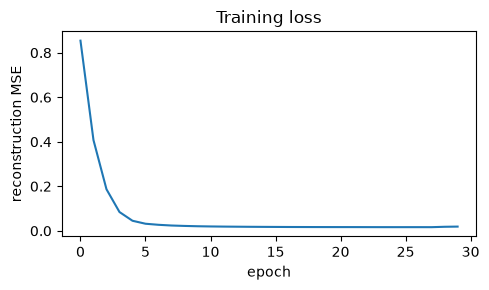

In [5]:
X_wave = cmp1[:, None, :].astype(np.float32)  # (N, 1, 256)
mu = X_wave.mean(axis=(0, 2), keepdims=True)
sigma = X_wave.std(axis=(0, 2), keepdims=True) + 1e-8
X_wave_n = (X_wave - mu) / sigma


class RFAutoencoder(nn.Module):
    # 1-D convolutional autoencoder for single-channel waveform anomaly detection.
    def __init__(self, latent_dim: int = 16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=8, stride=4, padding=2),
            nn.GELU(),
            nn.Conv1d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.GELU(),
            nn.Flatten(),
            nn.Linear(64 * 32, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 32),
            nn.Unflatten(1, (64, 32)),
            nn.ConvTranspose1d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.GELU(),
            nn.ConvTranspose1d(32, 1, kernel_size=8, stride=4, padding=2),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = RFAutoencoder()
loader = DataLoader(TensorDataset(torch.tensor(X_wave_n)), batch_size=32, shuffle=True)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 30
train_losses = []
model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    for (batch,) in loader:
        recon = model(batch)
        loss = nn.functional.mse_loss(recon, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch)
    train_losses.append(epoch_loss / len(X_wave_n))

plt.figure(figsize=(5, 3))
plt.plot(train_losses)
plt.xlabel("epoch"); plt.ylabel("reconstruction MSE"); plt.title("Training loss")
plt.tight_layout(); plt.show()

In [6]:
model.eval()
with torch.no_grad():
    recon = model(torch.tensor(X_wave_n))
    anomaly_score = ((torch.tensor(X_wave_n) - recon) ** 2).mean(dim=(1, 2)).numpy()

df["anomaly_score"] = anomaly_score
print(df.groupby("trig_code")["anomaly_score"].describe()[["count", "mean", "std"]])

print("\nTop-5 highest-scored events (exploratory, not a validated fault list):")
df.nlargest(5, "anomaly_score")[["trig_code", "beam_mode", "anomaly_score"]]

           count      mean       std
trig_code                           
14          20.0  0.057124  0.006170
15         190.0  0.014351  0.015587

Top-5 highest-scored events (exploratory, not a validated fault list):


,trig_code,beam_mode,anomaly_score
130,15,SlowCommissioning,0.073370
7,14,Probe,0.069334
9,14,Probe,0.069048
3,14,Probe,0.063364
12,14,Probe,0.062611


## Logging your score to Weights & Biases

The hackathon leaderboard (in Agora-Conf) reads from W&B. See `GRADING.md` at the repo
root for the full convention — in short: entity `artifact-hackathon-2026`, one project per
challenge (`anomaly-detection` here), and `group=` set to **your team's slug**, exactly as
shown on your team's page in Agora (copy the snippet from there — it already has your
`group` filled in). The official score is `anomaly/holdout_mse` on the held-out split in
`holdout_ids.json` (use `score.py`, or your own train/holdout split per `objectives.md`),
not the all-events `anomaly_score` this notebook computes — swap it in once you have it.

Your W&B API key is a team service account (shared by the whole team) handed out by the
organizers — set it as an environment variable, **never paste it into a notebook cell**.

In [ ]:
import os
import wandb

wandb.login(key=os.environ["WANDB_API_KEY"])  # set in your shell, never hardcode it here
run = wandb.init(
    entity="artifact-hackathon-2026",
    project="anomaly-detection",
    group="<your-team-slug>",  # from your team's page in Agora, e.g. "anomaly-hunters"
    config={"tier": "easy"},
)
# Placeholder: this notebook's all-events anomaly_score, not the held-out score.
# Replace with the output of score.py (or your own held-out split) once you have it.
wandb.log({"anomaly/holdout_mse": float(df["anomaly_score"].mean())})
run.finish()

## 6. A few more anomaly-detection methods

The autoencoder is one anomaly detector. Two classical baselines on the same feature
matrix — **Isolation Forest** and **Local Outlier Factor** — are a cheap way to see
whether "anomalous" is a robust notion here or an artifact of one model. This is the
kind of comparison the SPIRAL2 pipeline runs too (it uses Isolation Forest, LOF and
Mahalanobis distance as unsupervised baselines for its precursor task).

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from scipy.stats import spearmanr

iso = IsolationForest(n_estimators=200, contamination=0.1, random_state=42)
iso_score = -iso.fit(X_feat).score_samples(X_feat)  # higher = more anomalous

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
lof.fit_predict(X_feat)
lof_score = -lof.negative_outlier_factor_

df["iso_score"] = iso_score
df["lof_score"] = lof_score

print("Rank agreement between methods (Spearman correlation):")
for a, b in [("anomaly_score", "iso_score"), ("anomaly_score", "lof_score"), ("iso_score", "lof_score")]:
    rho, _ = spearmanr(df[a], df[b])
    print(f"  {a:14s} vs {b:10s}  rho={rho:+.2f}")
print("\nLow agreement is normal and worth discussing, not a bug -- each method defines")
print('"anomalous" differently (reconstruction error vs. isolation depth vs. local density).')

Rank agreement between methods (Spearman correlation):
  anomaly_score  vs iso_score   rho=+0.90
  anomaly_score  vs lof_score   rho=+0.35
  iso_score      vs lof_score   rho=+0.43

Low agreement is normal and worth discussing, not a bug -- each method defines
"anomalous" differently (reconstruction error vs. isolation depth vs. local density).


## 7. Unsupervised classification of anomalies — clustering

Flagging anomalies is only half the SPIRAL2-style pipeline — the other half is asking
whether the anomalies form **subtypes**. K-Means with a silhouette-score scan over a
few values of *k* on the engineered features, same idea as the SPIRAL2 pipeline's fault
subtype clustering (which found best *k* = 2 for every fault category it had enough
events for).

k=2  silhouette=0.618
k=3  silhouette=0.589
k=4  silhouette=0.582

Best k by silhouette: 2


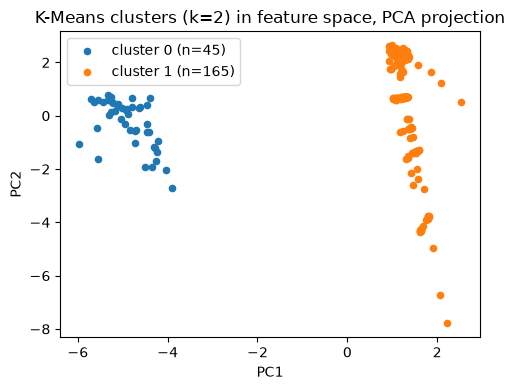


Cluster vs trig_code (exploratory -- trig_code is not a confirmed label):
trig_code  14   15
cluster           
0          20   25
1           0  165


In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

X_scaled = StandardScaler().fit_transform(X_feat)

sil_scores = {}
for k in (2, 3, 4):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels)
    print(f"k={k}  silhouette={sil_scores[k]:.3f}")

best_k = max(sil_scores, key=sil_scores.get)
print(f"\nBest k by silhouette: {best_k}")

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

coords = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(5, 4))
for cl in sorted(df["cluster"].unique()):
    mask = df["cluster"] == cl
    ax.scatter(coords[mask, 0], coords[mask, 1], label=f"cluster {cl} (n={mask.sum()})", s=20)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"K-Means clusters (k={best_k}) in feature space, PCA projection")
ax.legend()
plt.tight_layout(); plt.show()

print("\nCluster vs trig_code (exploratory -- trig_code is not a confirmed label):")
print(pd.crosstab(df["cluster"], df["trig_code"]))

## 8. Bonus: a weakly-supervised angle + explainability

If `trig_code` does turn out to be a meaningful operational label, here's what a simple
classifier on the engineered features picks up — and SHAP/LIME to see *why*, exactly the
explainability layer the SPIRAL2 pipeline uses (there: SHAP + LIME on an 810-feature
matrix; here, the same idea on 12 features).

In [9]:
y = df["trig_code"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X_feat, y, test_size=0.25, random_state=42, stratify=y
)

clf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
clf.fit(X_train.to_numpy(), y_train)
print(f"RF accuracy (trig_code group, {len(X_test)} held-out events): {clf.score(X_test.to_numpy(), y_test):.3f}")
print("Near-ceiling accuracy here likely means trig_code tracks an operating-mode distinction")
print("(RfTest/Probe/SlowCommissioning), not necessarily a subtle fault signal — worth asking Ishkhan.")

RF accuracy (trig_code group, 53 held-out events): 1.000
Near-ceiling accuracy here likely means trig_code tracks an operating-mode distinction
(RfTest/Probe/SlowCommissioning), not necessarily a subtle fault signal — worth asking Ishkhan.


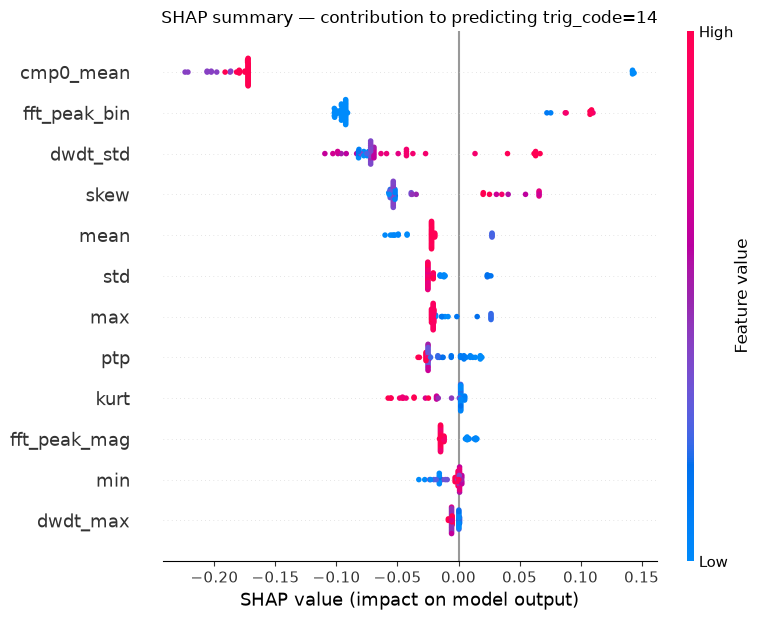

In [10]:
explainer = shap.TreeExplainer(clf)
shap_values = np.asarray(explainer.shap_values(X_test.to_numpy()))

# binary classifier -> shap_values is (n_samples, n_features, n_classes); pick one class
class_idx = list(clf.classes_).index(14)
shap_values_plot = shap_values[:, :, class_idx] if shap_values.ndim == 3 else shap_values

shap.summary_plot(shap_values_plot, X_test, show=False)
plt.title("SHAP summary — contribution to predicting trig_code=14")
plt.tight_layout(); plt.show()

In [11]:
lime_explainer = LimeTabularExplainer(
    X_train.to_numpy(),
    feature_names=list(X_feat.columns),
    class_names=[str(c) for c in sorted(set(y))],
    mode="classification",
)

idx = 0  # swap for any row of X_test you want to inspect
exp = lime_explainer.explain_instance(
    X_test.iloc[idx].to_numpy(), clf.predict_proba, num_features=8
)
print(f"LIME explanation for test event {idx} (true trig_code={y_test[idx]}):")
for feat, weight in exp.as_list():
    print(f"  {feat:30s} {weight:+.4f}")

LIME explanation for test event 0 (true trig_code=15):
  fft_peak_bin <= 1.00           +0.1383
  cmp0_mean <= 4.26              -0.0639
  skew > -0.73                   -0.0543
  std <= 19.70                   -0.0249
  max <= 93.11                   -0.0238
  mean <= 74.06                  -0.0230
  6.06 < dwdt_std <= 9.43        +0.0190
  kurt > 1.58                    +0.0171


## 9. Stretch — slow EPICS archiver data

`Archiver_Data` on the raw store holds slow EPICS trends (`RF_DET_Q_W`, `MAGNETS`,
`RF_PWR_FLD`, `LLRF_1`, ...) around the same time windows as the fast `SDS_Data` events
above. That's the ESS analog of the SPIRAL2 pipeline's **EPICS slow-archiver precursor
investigation** (their "Precursor Root-Cause Atlas") — looking for slow trends that
*precede* a trigger, rather than just describing the triggered event itself. Needs
CC-IN2P3 access to the raw archive; not covered in this notebook, but it's where the
harder objectives in `objectives.md` are headed.

## Next steps

- See `objectives.md` for the easy / medium / hard objectives
- Open question worth raising with Ishkhan: what `Cmp0`/`Cmp1` and `trig_code` actually
  mean — both were inferred from field names here, not confirmed
- Going deeper: this notebook deliberately stays light. The SPIRAL2 LLRF pipeline this
  was adapted from runs the full version of this idea — 810 features, 5 modeling tasks,
  a dedicated explainability layer — on a *different* accelerator (SPIRAL2, not ESS), so
  nothing there is directly portable, but the structure is a good reference:
  - [LLRF_SP2_pipeline](https://github.com/aghribi/LLRF_SP2_pipeline) — the production pipeline
  - [LLRF_SP2_report](https://github.com/aghribi/LLRF_SP2_report) — the companion paper source